# 02 - Input profiles

All profiles are synthetic and generated deterministically from the seed in `config.yaml`. The horizon runs noon-to-noon so overnight EV sessions fit in one optimization window.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils.config import load_config
from src.analysis import visualization as viz
viz.apply_style()
config = load_config(ROOT / "config" / "config.yaml")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
from src.utils.config import time_index
from src.profiles.load_profile import load_profile_from_config
from src.profiles.pv_profile import pv_profile_from_config
from src.profiles.price_profile import price_profile_from_config
t = time_index(config)
load = load_profile_from_config(config, t, commercial_share=0.485)
pv = pv_profile_from_config(config, t, installed_capacity_kw=1.0)
price = price_profile_from_config(config, t)
print(len(t), 'steps from', t[0], 'to', t[-1])
print(f'PV yield: {pv.pv_pu.sum()*0.25:.2f} kWh/kWp per day, peak {pv.pv_pu.max():.3f} kW/kWp')

96 steps from 2025-06-16 12:00:00 to 2025-06-17 11:45:00
PV yield: 6.84 kWh/kWp per day, peak 0.791 kW/kWp


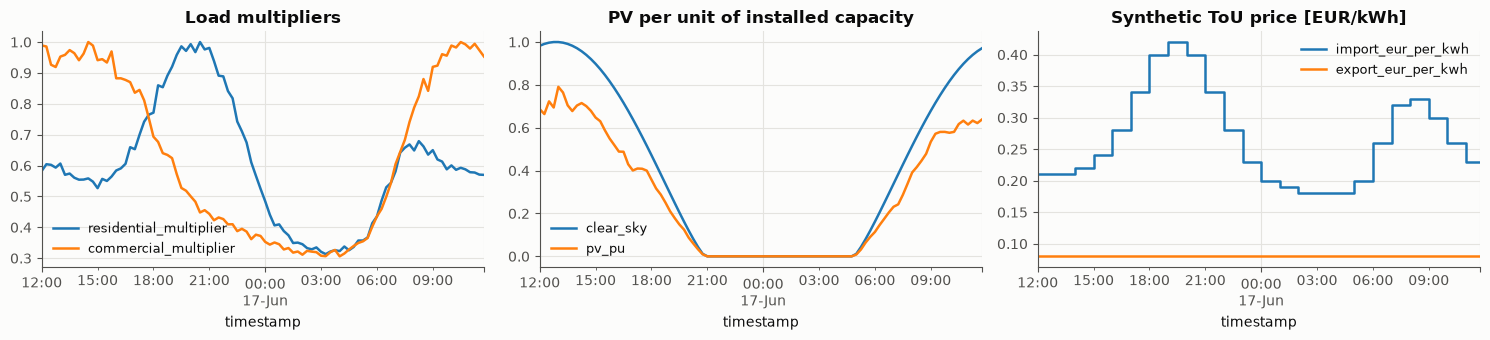

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
load[['residential_multiplier','commercial_multiplier']].plot(ax=axes[0], title='Load multipliers')
pv[['clear_sky','pv_pu']].plot(ax=axes[1], title='PV per unit of installed capacity')
price.plot(ax=axes[2], drawstyle='steps-post', title='Synthetic ToU price [EUR/kWh]')
plt.tight_layout(); plt.show()

In [4]:
from src.grid.network import build_network, residential_buses
from src.profiles.ev_profile import generate_ev_fleet
from src.models.ev_model import uncontrolled_charging
net = build_network(config); base = net.load.set_index('bus'); res = residential_buses(net)
fleet = generate_ev_fleet(config, t, config['ev']['levels']['high'], res, base.loc[res,'p_nom_mw'].tolist())
fleet[['bus','arrival','departure','capacity_kwh','initial_soc','max_power_kw','required_energy_kwh']].describe(include='all').T

,count,mean,min,25%,50%,75%,max,std
bus,150.0,15.3,1.0,8.0,16.0,21.0,32.0,8.728377
arrival,150,2025-06-16 18:07:24,2025-06-16 15:00:00,2025-06-16 17:15:00,2025-06-16 18:15:00,2025-06-16 19:00:00,2025-06-16 23:00:00,NaN
departure,150,2025-06-17 07:00:12,2025-06-17 05:00:00,2025-06-17 06:30:00,2025-06-17 07:00:00,2025-06-17 07:30:00,2025-06-17 09:00:00,NaN
capacity_kwh,150.0,58.866667,40.0,40.0,60.0,77.0,77.0,15.251215
initial_soc,150.0,0.350987,0.200297,0.269204,0.35008,0.424347,0.497015,0.089196
max_power_kw,150.0,9.008,7.4,7.4,7.4,11.0,11.0,1.795726
required_energy_kwh,150.0,26.3783,12.264641,19.153133,25.544489,32.982828,46.177154,8.5179


Uncontrolled EV peak 924 kW at 19:15; energy 4301 kWh

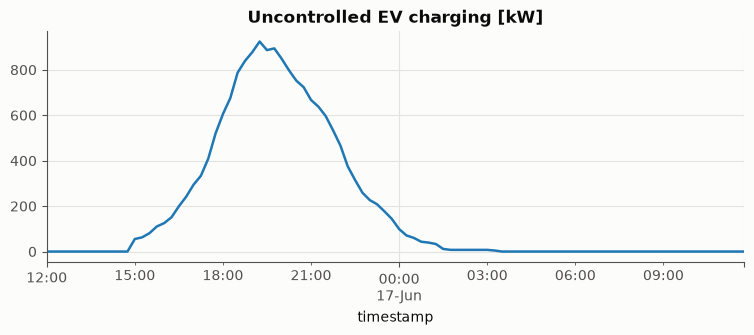

In [5]:
p = uncontrolled_charging(fleet, len(t), 0.25).sum(axis=0)
print(f'Uncontrolled EV peak {p.max():.0f} kW at {t[p.argmax()]:%H:%M}; energy {p.sum()*0.25:.0f} kWh')
pd.Series(p, index=t).plot(figsize=(9,3), title='Uncontrolled EV charging [kW]'); plt.show()